# Credit Pre-Screening Engine — MUC02 KLU
**Metla Kumara Swamy | Individual submission | 5 November 2026**

Predict historical analyst declines, choose a threshold under the bank's 5% error-share limit, and quantify workload and subgroup outcomes.

**Run:** Keep `MUC02_Credit_PreScreening_Dataset.csv` beside this notebook, install `requirements.txt`, then restart the kernel and run all cells. The notebook writes evidence tables to `supporting/`. Markdown findings describe the bundled dataset and execution; rerun outputs are the source of truth if inputs change.

**Scope:** The student assignment defines deliverables; the supplied trainer materials are reference context. All numerical conclusions below come from the supplied CSV, not copied reference answers. The target is past judgement, not repayment. This revision improves an existing notebook; placing the canvas first does not claim it was originally completed before coding.

## CBIM Problem Canvas

| CBIM field | Business framing |
|---|---|
| **Situation (S)** | A retail bank processes roughly 3,000 personal-loan applications per month; manual review takes about 25 minutes per application. |
| **Complication (C)** | Many clear-cut declines consume the same analyst time as complex cases; wrongly rejecting a potentially creditworthy applicant is costly. |
| **Question (Q)** | Which applications could safely bypass manual review, at what decline-probability threshold, and how many analyst hours could that free? |
| **SSOT** | The supplied 12,000-row application-history CSV. `decision` records *historical analyst judgment*, not actual loan repayment. |
| **Success definition** | Choose the threshold with the most coverage while no more than 5% of auto-declines were historically approved, then express savings in applications and hours. |
| **Stakeholders** | Credit Policy Analyst, Head of Retail Lending, reviewing analysts, and loan applicants. |

**Guardrail:** This is an educational decision-support analysis, **not** a ready-to-deploy automatic loan rejection system. A prospective validation and human appeal process would be required.

## 5.1 — Load, inspect and clean
Inspect the original data before changing anything. Preserve a raw copy, validate identifiers, dates and target labels, and reserve the required stratified 20% test set before learning income medians.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 50)

candidates = [Path('MUC02_Credit_PreScreening_Dataset.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Place the supplied credit screening CSV in the same folder as this notebook.')
df = pd.read_csv(data_path)
print('Source:', data_path.name, '| Shape:', df.shape)
display(df.head())
print('\nData types:'); print(df.dtypes.to_string())
print('\nMissing values:'); display(df.isna().sum().to_frame('null_count'))
print('\nDecision distribution:'); display(df['decision'].value_counts().to_frame('applications'))
print(f"Overall approval rate: {df['decision'].eq('Approved').mean():.1%}")

raw = df.copy(deep=True)
assert raw.application_id.is_unique, 'Duplicate application IDs require investigation.'
assert set(raw.decision.unique()) == {'Approved', 'Declined'}
dates = pd.to_datetime(raw.application_date, errors='raise')
print('Date range:', dates.min().date(), 'to', dates.max().date())
assert dates.between('2026-04-01', '2026-09-30').all()
from sklearn.model_selection import train_test_split
y = raw.decision.eq('Declined').astype(int)
train_idx, test_idx = train_test_split(raw.index, test_size=.2, stratify=y, random_state=42)
assert set(train_idx).isdisjoint(test_idx)
print('Reserved split:', len(train_idx), 'training /', len(test_idx), 'test')

Source: MUC02_Credit_PreScreening_Dataset.csv | Shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined



Data types:
application_id               str
application_date             str
age                        int64
gender                       str
city                         str
city_tier                  int64
employment_type              str
years_in_current_job     float64
monthly_income           float64
existing_emi             float64
credit_score             float64
credit_history_months      int64
num_active_loans           int64
delinquencies_24m          int64
loan_purpose                 str
loan_amount              float64
tenure_months              int64
proposed_emi             float64
decision                     str

Missing values:


,null_count
application_id,0
application_date,0
age,0
gender,0
city,0
city_tier,0
employment_type,0
years_in_current_job,0
monthly_income,441
existing_emi,0



Decision distribution:


,applications
decision,
Approved,6353
Declined,5647


Overall approval rate: 52.9%
Date range: 2026-04-01 to 2026-09-30
Reserved split: 9600 training / 2400 test


In [13]:
missing_income_by_type = df.groupby('employment_type').agg(
    applicants=('application_id', 'size'),
    missing_income=('monthly_income', lambda s: s.isna().sum()),
    median_income=('monthly_income', 'median'))
missing_income_by_type['missing_rate_pct'] = 100 * missing_income_by_type['missing_income'] / missing_income_by_type['applicants']
print('Missing income by employment type:'); display(missing_income_by_type.round(2))
ntc_rows = df['credit_score'].isna()
print('Blank credit scores:', ntc_rows.sum())
print('Credit history months for those blank scores:'); print(df.loc[ntc_rows, 'credit_history_months'].value_counts(dropna=False).to_string())
print('Maximum raw monthly income:', df['monthly_income'].max())
print('Incomes > ₹600,000:', int(df['monthly_income'].gt(600_000).sum()))
display(df.loc[df['monthly_income'] > 600_000, ['application_id', 'employment_type', 'monthly_income']].head(15))

# Correct likely annual-income-as-monthly entries, then impute the income by employment group's median.
annual_income_mask = df['monthly_income'] > 600_000
corrected_count = int(annual_income_mask.sum())
df.loc[annual_income_mask, 'monthly_income'] /= 12
missing_income_count = int(df['monthly_income'].isna().sum())
income_medians = df.loc[train_idx].groupby('employment_type')['monthly_income'].median()
income_fallback = df.loc[train_idx, 'monthly_income'].median()
df['monthly_income'] = df['monthly_income'].fillna(df.employment_type.map(income_medians)).fillna(income_fallback)
print('Income medians learned ONLY on training rows:'); display(income_medians)
assert df.loc[ntc_rows, 'credit_history_months'].eq(0).all()
assert len(df) == len(raw)
assert df.credit_score.notna().sum() == raw.credit_score.notna().sum()
assert df['monthly_income'].notna().all()
assert (df['monthly_income'] > 0).all()
print(f'Corrected {corrected_count} likely annual income values; imputed {missing_income_count} incomes; retained {ntc_rows.sum()} no-score applicants.')

Missing income by employment type:


,applicants,missing_income,median_income,missing_rate_pct
employment_type,,,,
Business Owner,1749,227,69500.0,12.98
Gig / Contract,1766,11,28000.0,0.62
Salaried,7057,49,50000.0,0.69
Self-Employed Professional,1428,154,75000.0,10.78


Blank credit scores: 1039
Credit history months for those blank scores:
credit_history_months
0    1039
Maximum raw monthly income: 1656000.0
Incomes > ₹600,000: 12


,application_id,employment_type,monthly_income
300,APP100301,Salaried,1254000.0
589,APP100590,Salaried,1068000.0
1467,APP101468,Salaried,1656000.0
1848,APP101849,Salaried,984000.0
2488,APP102489,Salaried,972000.0
2493,APP102494,Salaried,1212000.0
4010,APP104011,Salaried,900000.0
4898,APP104899,Salaried,870000.0
7426,APP107427,Salaried,690000.0
8381,APP108382,Salaried,618000.0


Income medians learned ONLY on training rows:


employment_type
Business Owner                71000.0
Gig / Contract                28500.0
Salaried                      50500.0
Self-Employed Professional    75250.0
Name: monthly_income, dtype: float64

Corrected 12 likely annual income values; imputed 441 incomes; retained 1039 no-score applicants.


**Cleaning decisions.** Keep all 12,000 applications. The 441 missing incomes are concentrated in self-employed and business-owner groups; fill them with their employment type's training-only median (global training median as a fallback), because income levels differ across occupations and medians resist extremes. Correct the 12 reported monthly incomes above INR 600,000 by dividing by 12 before fitting medians: all are salaried, suggesting annual income entered in a monthly field, but this is an assumption requiring source confirmation. Keep the 1,039 blank credit scores: all have zero credit-history months, so they represent new-to-credit applicants; median score imputation happens inside the model pipeline and `is_ntc` preserves that meaning.

**Evaluation hygiene.** The early split reserves the same rows used in 5.4; no test incomes inform the learned medians. Income uncertainty propagates into FOIR, so imputation is a practical approximation, not verified affordability. EDA describes the full history; test results used to choose the classroom threshold are not independent validation of that choice.

## 5.2 — What drives approval today?
Use the six required score bands plus No score, and compare employment types with group counts.

Approval by credit score:


,mean,count,approval_pct
score_band,,,
Below 600,0.02,246,2.03
600–649,0.03,933,3.22
650–699,0.33,2529,32.50
700–749,0.54,3377,54.37
750–799,0.77,2526,77.20
800+,0.85,1350,85.19
No score,0.54,1039,53.90


Approval by employment:


,mean,count,approval_pct
employment_type,,,
Gig / Contract,0.35,1766,34.94
Self-Employed Professional,0.51,1428,50.56
Business Owner,0.51,1749,51.17
Salaried,0.58,7057,58.37


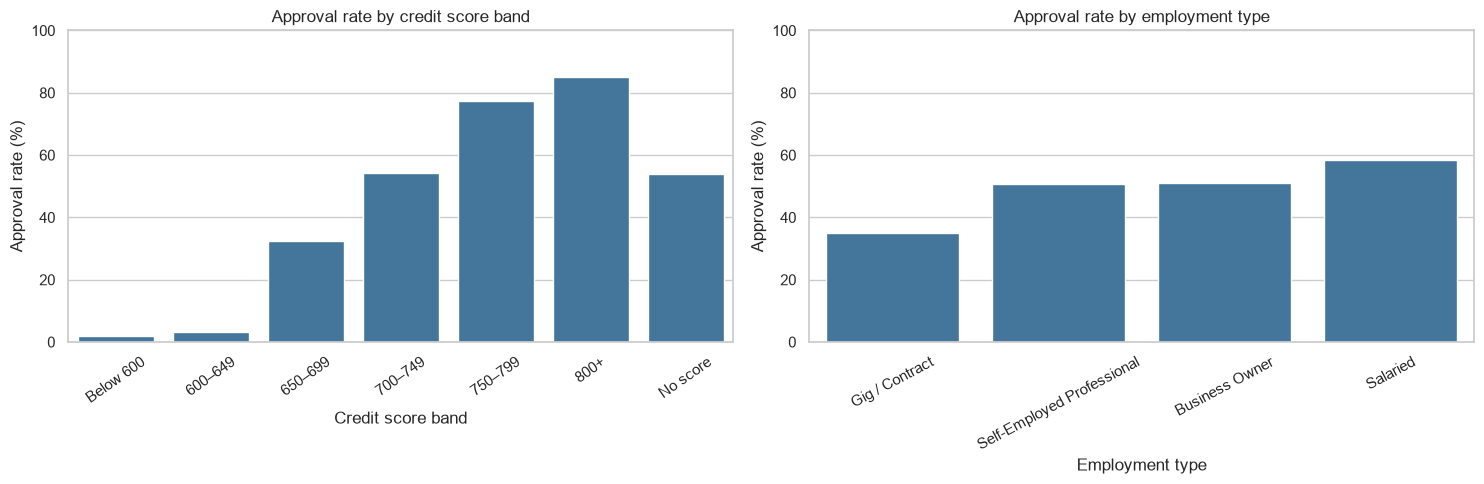

Approval under score 650: 3.0%
Approval for no-score: 53.9%


In [14]:
score_labels = ['Below 600', '600–649', '650–699', '700–749', '750–799', '800+', 'No score']
df['score_band'] = pd.cut(df['credit_score'], bins=[-np.inf, 600, 650, 700, 750, 800, np.inf], right=False,
                          labels=score_labels[:-1]).astype('object').fillna('No score')
df['approved'] = df['decision'].eq('Approved').astype(int)
score_approval = df.groupby('score_band')['approved'].agg(['mean','count']).reindex(score_labels)
employment_approval = df.groupby('employment_type')['approved'].agg(['mean','count']).sort_values('mean')
print('Approval by credit score:'); display(score_approval.assign(approval_pct=lambda x: x['mean']*100).round(2))
print('Approval by employment:'); display(employment_approval.assign(approval_pct=lambda x: x['mean']*100).round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=score_approval.index, y=score_approval['mean']*100, ax=axes[0], color='#3578a8')
axes[0].set(title='Approval rate by credit score band', ylabel='Approval rate (%)', xlabel='Credit score band', ylim=(0,100))
axes[0].tick_params(axis='x', rotation=35)
sns.barplot(x=employment_approval.index, y=employment_approval['mean']*100, ax=axes[1], color='#3578a8')
axes[1].set(title='Approval rate by employment type', ylabel='Approval rate (%)', xlabel='Employment type', ylim=(0,100))
axes[1].tick_params(axis='x', rotation=28)
plt.tight_layout(); plt.show()
print(f"Approval under score 650: {df.loc[df['credit_score'] < 650, 'approved'].mean():.1%}")
print(f"Approval for no-score: {df.loc[df['credit_score'].isna(), 'approved'].mean():.1%}")

**Findings.** Overall approval is 52.94%; the target is reasonably balanced. Only 2.97% of scored applicants below 650 are approved: approval rises from 3.22% in 600–649 to 32.50% in 650–699, consistent with an implicit score floor near 650. No-score applicants have 53.90% approval versus 52.85% for scored applicants overall, so absence of a score is not itself grounds to decline. Gig / Contract approval is 34.94% versus 58.37% for Salaried applicants; this association may reflect affordability and stability rather than a causal effect of the label.

## 5.3 — Engineer affordability features
Calculate FOIR, requested loan / annual income, and the new-to-credit flag. Bands are left-closed: exactly 30% belongs to 30–40%, and exactly 55% to the final band (labelled “55% and above” for precision).

,mean,count,approval_pct
foir_band,,,
Below 30%,0.65,5491,65.47
30–40%,0.59,2502,58.95
40–50%,0.48,1764,47.85
50–55%,0.33,529,32.51
55% and above,0.16,1714,15.58


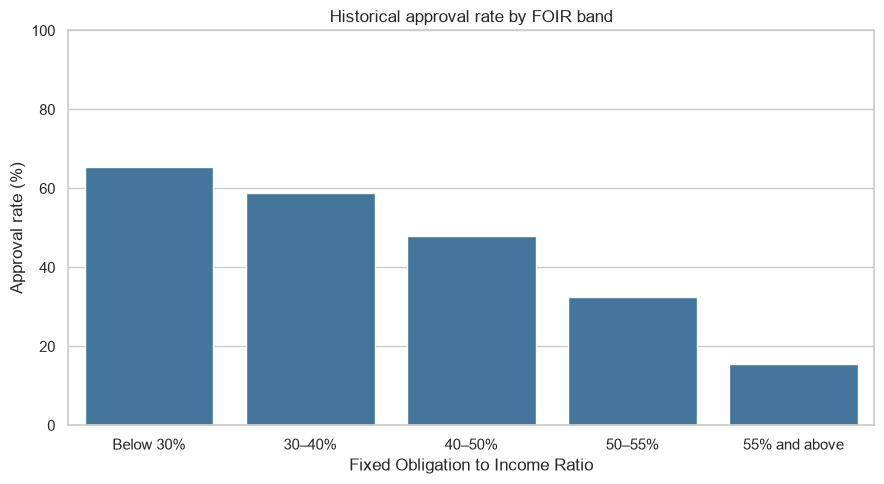

New-to-credit flag count: 1039


In [15]:
df['is_ntc'] = df['credit_score'].isna().astype(int)
df['foir'] = (df['existing_emi'] + df['proposed_emi']) / df['monthly_income']
df['loan_to_income'] = df['loan_amount'] / (df['monthly_income'] * 12)
foir_labels = ['Below 30%', '30–40%', '40–50%', '50–55%', '55% and above']
df['foir_band'] = pd.cut(df['foir'], bins=[-np.inf,.30,.40,.50,.55,np.inf], labels=foir_labels, right=False)
foir_approval = df.groupby('foir_band', observed=False)['approved'].agg(['mean','count'])
display(foir_approval.assign(approval_pct=lambda x:x['mean']*100).round(2))
plt.figure(figsize=(9, 5))
sns.barplot(x=foir_approval.index.astype(str), y=foir_approval['mean']*100, color='#3578a8')
plt.xlabel('Fixed Obligation to Income Ratio'); plt.ylabel('Approval rate (%)')
plt.title('Historical approval rate by FOIR band'); plt.ylim(0,100); plt.tight_layout(); plt.show()
print('New-to-credit flag count:', df['is_ntc'].sum())

assert np.isfinite(df[['foir','loan_to_income']].to_numpy()).all()

**Policy interpretation.** Approval falls from 65.47% below 30% FOIR to 47.85% at 40–50%, 32.51% at 50–55%, and 15.58% at 55% or above. I propose 50% as a normal affordability ceiling for straightforward cases, with 50–55% requiring explicit analyst judgement and anything higher escalated for affordability review. This proposed policy boundary describes the historical pattern; it is not a separately validated automatic rejection rule. FOIR measures repayment burden, loan-to-income measures requested leverage, and `is_ntc` separates genuinely absent history from an imputed typical score.

## 5.4 — Logistic regression pre-screener
Use exactly the prescribed predictors and Declined = 1. Income is used to derive affordability, not added as an extra model predictor; gender and other prohibited columns are excluded. Train-only numeric imputation and scaling plus one-hot categorical encoding feed a single logistic regression; the held-out split is 80/20, stratified, seed 42.

Test set: 2400 applications | target 1=Declined


,accuracy,precision_declined,recall_declined,roc_auc
0,0.7908,0.7916,0.7538,0.8674


Confusion matrix rows=actual, columns=predicted [Approved, Declined]:
 [[1047  224]
 [ 278  851]]

Classification report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



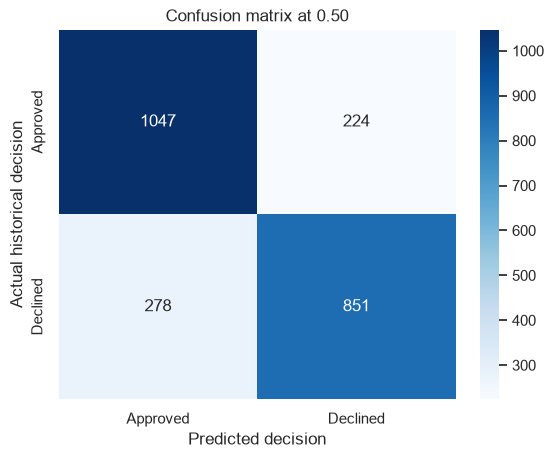

IMPORTANT: 224 historically approved customers would be wrongly declined at threshold 0.50.


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, roc_auc_score, classification_report

numeric_features = ['credit_score','is_ntc','foir','loan_to_income','delinquencies_24m',
                    'num_active_loans','years_in_current_job','age','tenure_months','city_tier']
categorical_features = ['employment_type','loan_purpose']
feature_names = numeric_features + categorical_features
X = df[feature_names].copy()
y = df['decision'].eq('Declined').astype(int)  # 1=Declined, 0=Approved
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
assert not set(['gender','city','application_id','application_date','decision']).intersection(X.columns)

# Median blank score is calculated on training data only, preventing test-data leakage.
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
category_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocess = ColumnTransformer([('numeric', numeric_pipeline, numeric_features),
                                ('categorical', category_pipeline, categorical_features)])
model = Pipeline([('preprocess', preprocess), ('logreg', LogisticRegression(max_iter=2000, random_state=42))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
p_decline = model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
model_metrics = {'accuracy':accuracy_score(y_test,y_pred),
                 'precision_declined':precision_score(y_test,y_pred,pos_label=1),
                 'recall_declined':recall_score(y_test,y_pred,pos_label=1),
                 'roc_auc':roc_auc_score(y_test,p_decline)}
print('Test set:', len(y_test), 'applications | target 1=Declined')
display(pd.DataFrame([model_metrics]).round(4))
print('Confusion matrix rows=actual, columns=predicted [Approved, Declined]:\n', cm)
print('\nClassification report:'); print(classification_report(y_test,y_pred,target_names=['Approved','Declined']))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Approved','Declined'], yticklabels=['Approved','Declined'])
plt.xlabel('Predicted decision'); plt.ylabel('Actual historical decision'); plt.title('Confusion matrix at 0.50'); plt.show()
print(f'IMPORTANT: {cm[0,1]} historically approved customers would be wrongly declined at threshold 0.50.')

**Business interpretation at 0.50.** Of 2,400 test applicants, 1,047 historically approved cases are correctly classified, but **224 historically approved applicants would be wrongly declined**; 278 historical declines are missed and 851 are detected. Accuracy is 79.08%, decline precision 79.16%, decline recall 75.38%, and ROC-AUC 0.867. “Approved” here means approved by past analysts, not proven creditworthy from repayment evidence. The missed declines would still receive manual review in the proposed workflow; the false declines are the more direct customer harm.

### Coefficients and vulnerable segment
Rank coefficients by absolute size, retaining their signs. Numeric coefficients refer to a one-standard-deviation increase; categorical dummy coefficients refer to their encoded indicator. With full one-hot encoding, interpret category contrasts as differences between category coefficients, not as an omitted reference category; coefficient magnitude across numeric and dummy features is not a universal importance ranking.

Five largest coefficient magnitudes:


,coefficient
numeric__foir,1.220190
numeric__credit_score,-1.010216
numeric__delinquencies_24m,0.978968
categorical__employment_type_Gig / Contract,0.618046
categorical__employment_type_Salaried,-0.445793


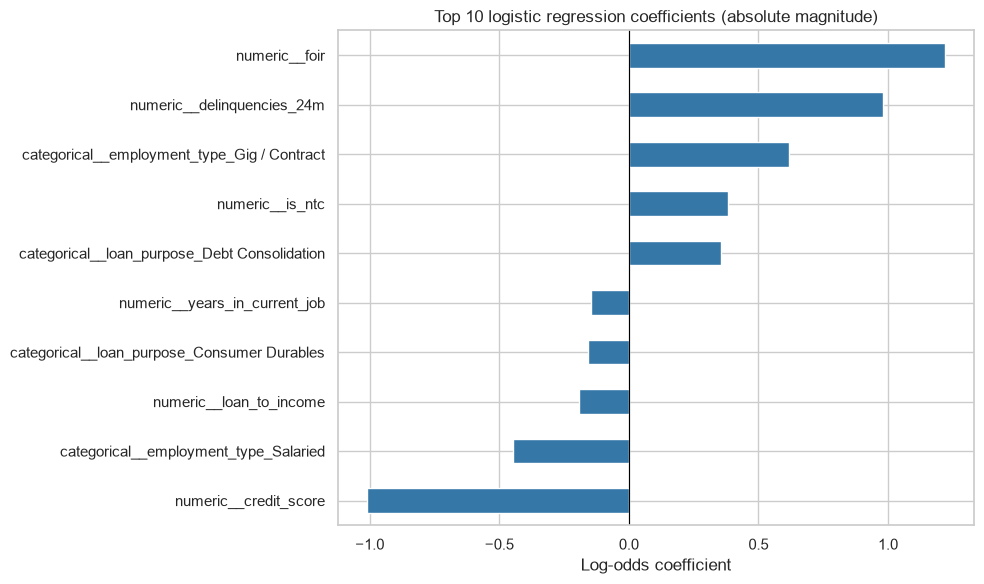

numeric__foir: +1.220 → higher predicted decline odds (holding other modeled features fixed)
numeric__credit_score: -1.010 → lower predicted decline odds (holding other modeled features fixed)
numeric__delinquencies_24m: +0.979 → higher predicted decline odds (holding other modeled features fixed)
categorical__employment_type_Gig / Contract: +0.618 → higher predicted decline odds (holding other modeled features fixed)
categorical__employment_type_Salaried: -0.446 → lower predicted decline odds (holding other modeled features fixed)
Scored-applicant accuracy: 0.812
New-to-credit accuracy: 0.567


In [17]:
feature_out = model.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.Series(model.named_steps['logreg'].coef_.ravel(), index=feature_out).sort_values(key=np.abs, ascending=False)
print('Five largest coefficient magnitudes:'); display(coefficients.head(5).to_frame('coefficient'))
plt.figure(figsize=(10,6))
coefficients.head(10).sort_values().plot.barh(color='#3578a8')
plt.axvline(0,color='black',linewidth=.8); plt.xlabel('Log-odds coefficient')
plt.title('Top 10 logistic regression coefficients (absolute magnitude)'); plt.tight_layout(); plt.show()
for name, value in coefficients.head(5).items():
    print(f'{name}: {value:+.3f} → {"higher predicted decline odds" if value > 0 else "lower predicted decline odds"} (holding other modeled features fixed)')
print('Scored-applicant accuracy:', round(accuracy_score(y_test[X_test['is_ntc'].eq(0)], y_pred[X_test['is_ntc'].eq(0)]), 3))
print('New-to-credit accuracy:', round(accuracy_score(y_test[X_test['is_ntc'].eq(1)], y_pred[X_test['is_ntc'].eq(1)]), 3))

**What the five largest coefficients mean.** A one-standard-deviation increase in FOIR has coefficient +1.220 (about 3.39× decline odds), higher credit score −1.010 (0.36×), and more delinquencies +0.979 (2.66×), with other model inputs held fixed. Gig / Contract has coefficient +0.618 and Salaried −0.446; their difference implies approximately 2.90× higher model decline odds for Gig than Salaried applicants with the same other model inputs. These are conditional model associations, not causal effects or necessarily calibrated probability multipliers.

Scored-applicant accuracy is **81.16%** (2,197 cases), but new-to-credit accuracy is **56.65%** (203 cases), only modestly above that group's 53.69% majority-class baseline. This supports preserving human judgement for NTC applicants.

## 5.5 — Set the auto-decline threshold
Compare the seven required thresholds. The risk measure is **historically approved among auto-declines / all auto-declines**; it is not the false-positive rate among all approved applicants. Maximise auto-decline coverage subject to the observed error share being at most 5%.

,threshold,auto_declined_count,auto_declined_pct,wrongly_declined_count,wrong_among_auto_pct
0,0.50,1075,44.79,224,20.84
1,0.60,902,37.58,152,16.85
2,0.70,738,30.75,89,12.06
3,0.80,564,23.50,39,6.91
4,0.85,472,19.67,28,5.93
5,0.90,365,15.21,17,4.66
6,0.95,241,10.04,5,2.07


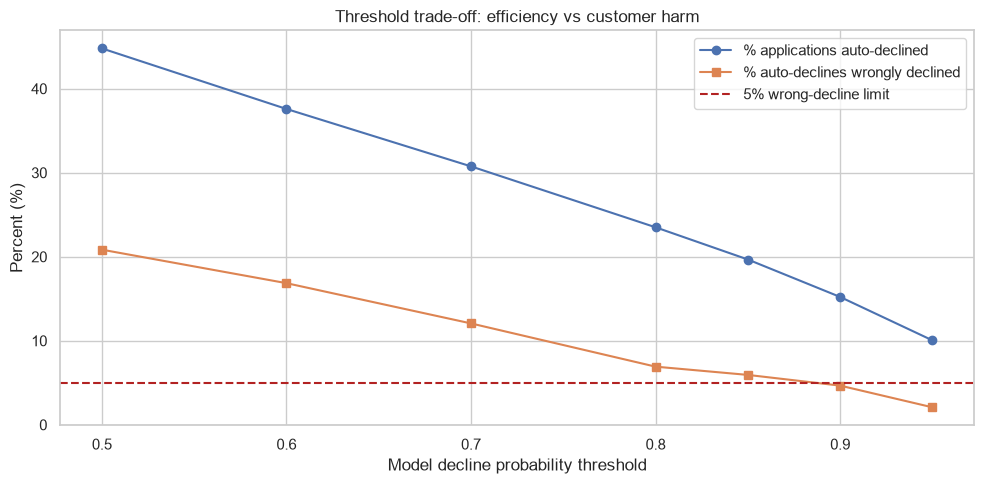

Recommended threshold: 0.90 | 15.2% auto-declined | 4.7% wrong within auto-declines
Business impact: ~456 fewer manual reviews / month; ~190 analyst hours / month.


In [18]:
thresholds = [.50,.60,.70,.80,.85,.90,.95]
rows = []
for t in thresholds:
    auto = p_decline >= t
    num_auto = int(auto.sum())
    wrong = int(((y_test.to_numpy() == 0) & auto).sum())
    rows.append({'threshold':t, 'auto_declined_count':num_auto,
                 'auto_declined_pct':100*num_auto/len(y_test),
                 'wrongly_declined_count':wrong,
                 'wrong_among_auto_pct':100*wrong/num_auto if num_auto else np.nan})
threshold_table = pd.DataFrame(rows)
display(threshold_table.round(2))
fig, ax=plt.subplots(figsize=(10,5))
ax.plot(threshold_table['threshold'],threshold_table['auto_declined_pct'],marker='o',label='% applications auto-declined')
ax.plot(threshold_table['threshold'],threshold_table['wrong_among_auto_pct'],marker='s',label='% auto-declines wrongly declined')
ax.axhline(5,ls='--',color='firebrick',label='5% wrong-decline limit')
ax.set(xlabel='Model decline probability threshold',ylabel='Percent (%)',title='Threshold trade-off: efficiency vs customer harm')
ax.legend(); plt.tight_layout(); plt.show()

eligible = threshold_table.loc[threshold_table['wrong_among_auto_pct'].le(5) & threshold_table['auto_declined_count'].gt(0)]
if eligible.empty:
    chosen_threshold = None
    print('No tested threshold meets the bank risk rule; recommend manual review only.')
else:
    choice = eligible.sort_values(['auto_declined_count','threshold'],ascending=[False, True]).iloc[0]
    chosen_threshold = float(choice['threshold'])
    applications_saved = 3000 * float(choice['auto_declined_pct']) / 100
    hours_saved = applications_saved * 25/60
    print(f"Recommended threshold: {chosen_threshold:.2f} | {choice['auto_declined_pct']:.1f}% auto-declined | {choice['wrong_among_auto_pct']:.1f}% wrong within auto-declines")
    print(f'Business impact: ~{applications_saved:,.0f} fewer manual reviews / month; ~{hours_saved:,.0f} analyst hours / month.')

**Decision: 0.90.** It flags 365 of 2,400 applications (15.21%), including 17 historically approved applicants: **4.66% wrong among auto-declines**. At 0.85 the error share is 5.93%, above the limit; 0.95 meets the limit but flags fewer cases, so 0.90 maximises coverage among the seven candidates.

**Monthly base-case business value:** 3,000 × 365 / 2,400 = **456.25 applications**, or **190.10 analyst hours** at 25 minutes each (about 15.21% of the 1,250-hour baseline). The same extrapolation implies about **21.25 historically approved applicants wrongly declined per month**, not zero harm. These are expected workload equivalents under unchanged case mix, not guaranteed staffing savings. All cases below the threshold remain in manual review; the model does not auto-approve them.

### Additional evidence: sampling uncertainty and NTC manual-review safeguard
The required table covers all applicants. Separately quantify the proposed safeguard of retaining every new-to-credit applicant for human review, so its workload savings are not confused with the assignment's base policy. A Wilson interval describes binomial sampling uncertainty at the selected threshold; it does not correct for threshold selection or distribution change.

In [19]:
def wilson_interval(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z*z/n
    centre = (p + z*z/(2*n))/d
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return centre-half, centre+half

policy_rows = []
if chosen_threshold is not None:
    for name, mask in [
        ('Assignment: all applicants', p_decline >= chosen_threshold),
        ('Safeguard: scored applicants only', (p_decline >= chosen_threshold) & X_test.is_ntc.eq(0).to_numpy())
    ]:
        n = int(mask.sum())
        k = int((mask & y_test.eq(0).to_numpy()).sum())
        lo, hi = wilson_interval(k, n)
        policy_rows.append(dict(policy=name, auto_count=n, wrong_count=k,
            auto_pct=100*n/len(y_test), wrong_pct=100*k/n if n else np.nan,
            wrong_ci_low_pct=100*lo, wrong_ci_high_pct=100*hi,
            monthly_applications=3000*n/len(y_test), monthly_hours=3000*n/len(y_test)*25/60,
            monthly_wrong=3000*k/len(y_test)))
policy_table = pd.DataFrame(policy_rows)
display(policy_table.round(2))
ntc_comparison = []
for flag, name in [(0, 'Scored'), (1, 'New to credit')]:
    mask = X_test.is_ntc.eq(flag)
    ntc_comparison.append(dict(group=name, n=int(mask.sum()),
        accuracy=accuracy_score(y_test[mask], y_pred[mask]),
        majority_baseline=max(y_test[mask].mean(),1-y_test[mask].mean())))
ntc_comparison = pd.DataFrame(ntc_comparison)
display(ntc_comparison.round(4))

,policy,auto_count,wrong_count,auto_pct,wrong_pct,wrong_ci_low_pct,wrong_ci_high_pct,monthly_applications,monthly_hours,monthly_wrong
0,Assignment: all applicants,365,17,15.21,4.66,2.93,7.33,456.25,190.10,21.25
1,Safeguard: scored applicants only,353,11,14.71,3.12,1.75,5.49,441.25,183.85,13.75


,group,n,accuracy,majority_baseline
0,Scored,2197,0.8116,0.5289
1,New to credit,203,0.5665,0.5369


**Risk and operational recommendation.** The all-applicant wrong-decline share has an approximate 95% Wilson interval of **2.93–7.33%**, so the observed result meeting 5% does not establish that the true rate is below 5%. Threshold selection on this same test set makes a fresh prospective evaluation necessary.

Keeping every NTC applicant with an analyst removes 12 auto-declines, including 6 mistakes. The scored-only safeguard flags **353 cases**, with **11 mistakes (3.12%)**, equivalent to **441 applications and 184 hours monthly**, with about 14 wrong declines monthly under unchanged case mix. Its interval is **1.75–5.49%**, still crossing 5%; recommend a monitored pilot with human review, not immediate unattended rejection. The required all-applicant result and this safeguarded proposal are reported separately.

## 5.6 — Fairness check
Compare historical approvals overall and within employment type, income medians and gig-worker shares. Evaluate auto-declines on the test set, then compare historical decline gaps on those same rows to avoid mixing samples.

Overall historical approval by gender:


,mean,size,approval_pct
gender,,,
Female,0.50,3795,50.43
Male,0.54,8205,54.10


Approval within employment categories by gender (%):


gender,Female,Male
employment_type,,
Business Owner,51.62,51.05
Gig / Contract,34.65,35.18
Salaried,56.79,59.06
Self-Employed Professional,47.63,51.97


Median monthly income by gender (₹):


,median_monthly_income
gender,
Female,45000.0
Male,55000.0


Gig / Contract share by gender (%):


,gig_share_pct
gender,
Female,21.37
Male,11.64


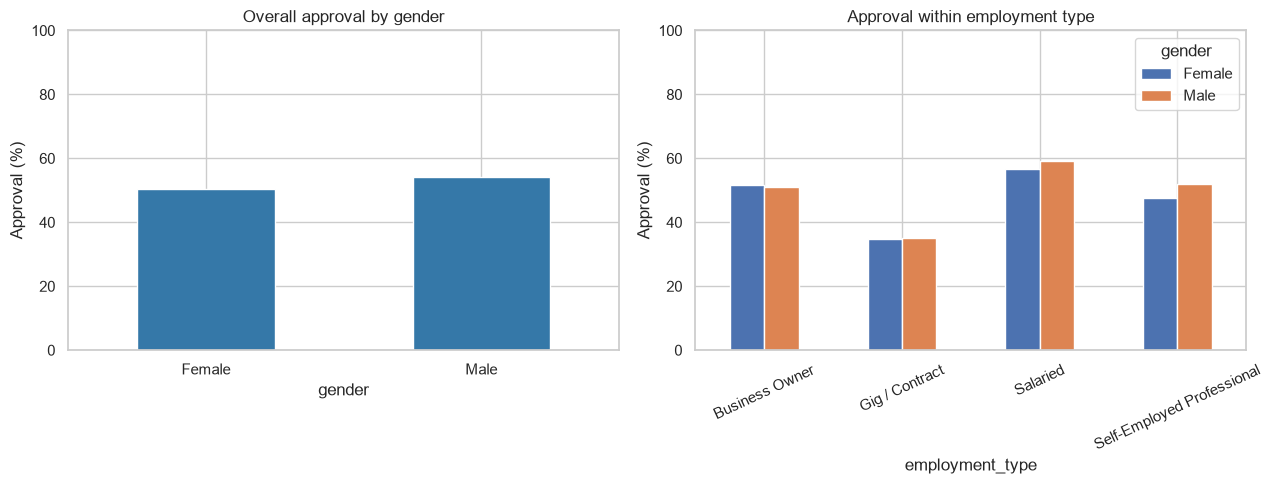

Auto-decline rate by gender at threshold 0.90:


,count,auto_decline_rate,auto_decline_pct
gender,,,
Female,750,0.16,15.60
Male,1650,0.15,15.03


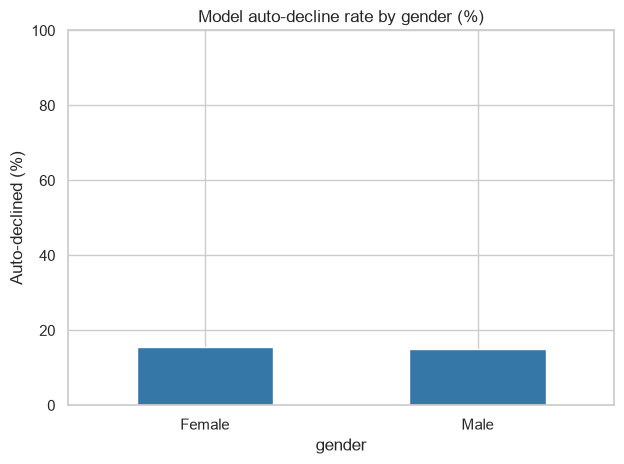

Same-test-set comparison (manual review is NOT an approval):


,n,historical_decline_pct,auto_decline_pct
gender,,,
Female,750,49.73,15.60
Male,1650,45.82,15.03


Within-employment group sizes:


gender,Female,Male
employment_type,,
Business Owner,370,1379
Gig / Contract,811,955
Salaried,2150,4907
Self-Employed Professional,464,964


In [20]:
gender_overall = df.groupby('gender')['approved'].agg(['mean','size'])
gender_within_employment = df.pivot_table(index='employment_type', columns='gender', values='approved', aggfunc='mean')
gender_income = df.groupby('gender')['monthly_income'].median()
gig_share = df.assign(is_gig=df['employment_type'].eq('Gig / Contract')).groupby('gender')['is_gig'].mean()
print('Overall historical approval by gender:'); display((gender_overall.assign(approval_pct=lambda x:100*x['mean'])).round(2))
print('Approval within employment categories by gender (%):'); display((gender_within_employment*100).round(2))
print('Median monthly income by gender (₹):'); display(gender_income.to_frame('median_monthly_income'))
print('Gig / Contract share by gender (%):'); display((100*gig_share).round(2).to_frame('gig_share_pct'))
fig,ax=plt.subplots(1,2,figsize=(13,5))
(gender_overall['mean']*100).plot.bar(ax=ax[0],color='#3578a8'); ax[0].set(title='Overall approval by gender',ylabel='Approval (%)',ylim=(0,100)); ax[0].tick_params(axis='x',rotation=0)
(gender_within_employment*100).plot.bar(ax=ax[1]); ax[1].set(title='Approval within employment type',ylabel='Approval (%)',ylim=(0,100)); ax[1].tick_params(axis='x',rotation=25)
plt.tight_layout(); plt.show()
if chosen_threshold is not None:
    fairness_test = df.loc[X_test.index, ['gender', 'employment_type','approved']].copy()
    fairness_test['auto_declined'] = (p_decline >= chosen_threshold).astype(int)
    fairness_by_gender = fairness_test.groupby('gender').agg(count=('auto_declined','size'), auto_decline_rate=('auto_declined','mean'))
    print(f'Auto-decline rate by gender at threshold {chosen_threshold:.2f}:'); display(fairness_by_gender.assign(auto_decline_pct=lambda x:100*x['auto_decline_rate']).round(2))
    fairness_by_gender['auto_decline_rate'].mul(100).plot.bar(color='#3578a8',title='Model auto-decline rate by gender (%)',ylim=(0,100))
    plt.ylabel('Auto-declined (%)'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

if chosen_threshold is not None:
    fairness_test['historical_decline'] = 1-fairness_test['approved']
    comparable_gender = fairness_test.groupby('gender').agg(
        n=('approved','size'), historical_decline_pct=('historical_decline', lambda s:100*s.mean()),
        auto_decline_pct=('auto_declined', lambda s:100*s.mean()))
    print('Same-test-set comparison (manual review is NOT an approval):')
    display(comparable_gender.round(2))
print('Within-employment group sizes:')
display(pd.crosstab(df.employment_type, df.gender))

**Fairness interpretation (four sentences).** Historical approval is 54.10% for men and 50.43% for women, a 3.67 percentage-point gap; within Business Owner and Gig / Contract groups the absolute gaps are below 0.6 points, although the Self-Employed Professional gap remains 4.34 points. Women's median income is INR 45,000 versus INR 55,000 for men, and their gig-worker share is 21.37% versus 11.64%, consistent with composition explaining some of the difference but not proving its cause. On the same test rows, the female-minus-male historical decline gap is 3.92 points while the model auto-decline gap at 0.90 is 0.57 points (15.60% versus 15.03%), so this measured rejection-rate gap narrows, but cases sent to manual review are not approvals and the final end-to-end approval gap remains unknown. Gender should not be a decision input in this model, but excluding it does not remove proxy effects from income-derived or employment features; retain it separately for outcome auditing and review subgroup mistakes.

### Subgroup mistakes
Show both error share among auto-declines and false-auto-declines among historically approved applicants; unequal group sizes affect uncertainty.

In [21]:
# Additional audit: quantify WRONG auto-declines across gender groups, not only coverage.
if chosen_threshold is not None:
    audit = df.loc[X_test.index, ['gender']].copy()
    audit['historically_approved'] = y_test.eq(0).to_numpy()
    audit['auto_declined'] = p_decline >= chosen_threshold
    audit['wrong_auto_decline'] = audit['historically_approved'] & audit['auto_declined']
    group_audit = audit.groupby('gender').agg(
        total=('gender','size'), auto_declined=('auto_declined','sum'),
        wrongly_declined=('wrong_auto_decline','sum'), approved=('historically_approved','sum'))
    group_audit['wrong_within_auto_pct'] = 100 * group_audit['wrongly_declined'] / group_audit['auto_declined'].replace(0, np.nan)
    group_audit['approved_wrongly_flagged_pct'] = 100 * group_audit['wrongly_declined'] / group_audit['approved'].replace(0, np.nan)
    display(group_audit.round(2))
    print('Caution: Small subgroup counts mean observed differences have sampling uncertainty.')
    group_audit['auto_pct'] = 100*group_audit.auto_declined/group_audit.total
    bounds = [wilson_interval(int(r.wrongly_declined), int(r.auto_declined)) for r in group_audit.itertuples()]
    group_audit['wrong_ci_low_pct'] = [100*b[0] for b in bounds]
    group_audit['wrong_ci_high_pct'] = [100*b[1] for b in bounds]
    display(group_audit.round(2))

,total,auto_declined,wrongly_declined,approved,wrong_within_auto_pct,approved_wrongly_flagged_pct
gender,,,,,,
Female,750,117,4,377,3.42,1.06
Male,1650,248,13,894,5.24,1.45


Caution: Small subgroup counts mean observed differences have sampling uncertainty.


,total,auto_declined,wrongly_declined,approved,wrong_within_auto_pct,approved_wrongly_flagged_pct,auto_pct,wrong_ci_low_pct,wrong_ci_high_pct
gender,,,,,,,,,
Female,750,117,4,377,3.42,1.06,15.60,1.34,8.46
Male,1650,248,13,894,5.24,1.45,15.03,3.09,8.76


**Subgroup conclusion.** Wrong-auto-decline shares are 4/117 = **3.42% for women** and 13/248 = **5.24% for men**; among historically approved applicants, 1.06% of women and 1.45% of men are falsely flagged. The aggregate 4.66% result therefore hides one subgroup point estimate above 5%, even though the assignment's constraint applies overall. Small error counts and overlapping intervals prevent a strong conclusion about a persistent difference; audit a larger future cohort and the scored-only safeguard before launch. Similar auto-decline coverage alone is not evidence of equal error rates.

## 5.7 — Briefing evidence and reproducibility
Collect the verified findings and export supporting tables. The final markdown cell is the requested six-sentence Credit Policy Briefing.

In [22]:
import json, hashlib, platform, importlib.metadata
support = Path('supporting')
support.mkdir(exist_ok=True)
tables = {'thresholds':threshold_table, 'policies':policy_table,
          'score_approval':score_approval, 'employment_approval':employment_approval,
          'foir_approval':foir_approval, 'gender_overall':gender_overall,
          'gender_within_employment':gender_within_employment,
          'gender_audit':group_audit, 'gender_comparable_test':comparable_gender,
          'coefficients':coefficients.to_frame('coefficient'), 'ntc_comparison':ntc_comparison,
          'missing_income':missing_income_by_type}
for name, table in tables.items():
    table.to_csv(support / (name+'.csv'), index=True)
results = dict(metrics=model_metrics, cm=cm.tolist(),
    threshold=chosen_threshold, choice=choice.to_dict(), policies=policy_table.to_dict('records'),
    approval_rate=float(df.approved.mean()),
    score=score_approval['mean'].to_dict(), employment=employment_approval['mean'].to_dict(),
    foir=foir_approval['mean'].to_dict(), coefficients=coefficients.head(5).to_dict(),
    below650=float(df.loc[df.credit_score.lt(650),'approved'].mean()),
    scored_approval=float(df.loc[df.is_ntc.eq(0),'approved'].mean()),
    gender_approval=gender_overall['mean'].to_dict(), gender_income=gender_income.to_dict(),
    gig_share=gig_share.to_dict(), comparable=comparable_gender.to_dict('index'),
    audit=group_audit.to_dict('index'), ntc=ntc_comparison.to_dict('records'),
    sha256=hashlib.sha256(data_path.read_bytes()).hexdigest(),
    python=platform.python_version(),
    versions={p:importlib.metadata.version(p) for p in ['pandas','numpy','matplotlib','seaborn','scikit-learn','nbformat','nbclient','nbconvert','ipykernel']})
assert len(X_train)==9600 and len(X_test)==2400
assert int(cm.sum())==len(y_test)
assert np.isfinite(p_decline).all()
assert chosen_threshold in thresholds and choice['wrong_among_auto_pct'] <= 5
assert choice['auto_declined_count'] == eligible.auto_declined_count.max()
(support/'results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
print('All consistency checks passed. Evidence tables saved to', support.resolve())
print('Dataset SHA256:', results['sha256'])

All consistency checks passed. Evidence tables saved to /Users/kumar/Downloads/KLU USECASE-2/MetlaKumaraSwamy_MUC02_KLU_Submission/supporting
Dataset SHA256: 17b1e2921cc95e43a2171667753e4ca31eeadbd172418baa8a32329d8d1162df


## Credit Policy Briefing
I recommend a 0.90 decline-probability threshold for a monitored pilot: the required all-applicant analysis flags 15.21%, equivalent to about 456 of 3,000 monthly applications and 190 analyst hours, with 17 of 365 auto-declines wrongly flagged (4.66%). Credit score and affordability are the strongest model drivers: only 2.97% of applicants scoring below 650 are approved, and approval falls from 65.47% below 30% FOIR to 15.58% at 55% or higher. Keep new-to-credit applicants with human reviewers because their test accuracy is only 56.65%; this safeguard reduces the projected workload saving to about 441 applications and 184 hours monthly, with 11 mistakes among 353 flagged cases (3.12%). Gender exclusion is insufficient: auto-decline rates are 15.60% for women and 15.03% for men, but the male wrong-decline share is 5.24%, so monitor subgroup errors and offer review of contested decisions. The overall 95% error-share interval extends to 7.33%, and the threshold was selected on this test sample, so validate it on a fresh future cohort before automating declines. Before going live, collect repayment/default outcomes because this model currently reproduces historical analyst judgement rather than measuring whether customers repay.